In [12]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import sawtooth
import pandas as pd
from pathlib import Path
import os


### a) Construcción de una señal cuadrada periódica


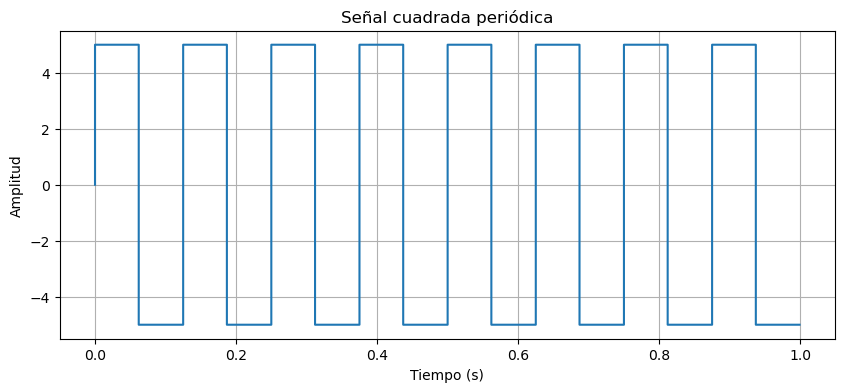

In [4]:

# Parámetros de la señal
f0 = 8          # Frecuencia fundamental en Hz
A = 5          # Amplitud de la señal
N = 1000        # Número de muestras
fs = 1000       # Frecuencia de muestreo en Hz

# Vector de tiempo
t = np.arange(N) / fs

# Construcción de la señal cuadrada
x = A * np.sign(np.sin(2 * np.pi * f0 * t))

# Gráfica de la señal
plt.figure(figsize=(10, 4))
plt.plot(t, x, drawstyle="steps-pre")
plt.title("Señal cuadrada periódica")
plt.xlabel("Tiempo (s)")
plt.ylabel("Amplitud")
plt.grid(True)
plt.ylim(-A - 0.5, A + 0.5)
plt.show()



### b) Construcción de una señal triangular periódica



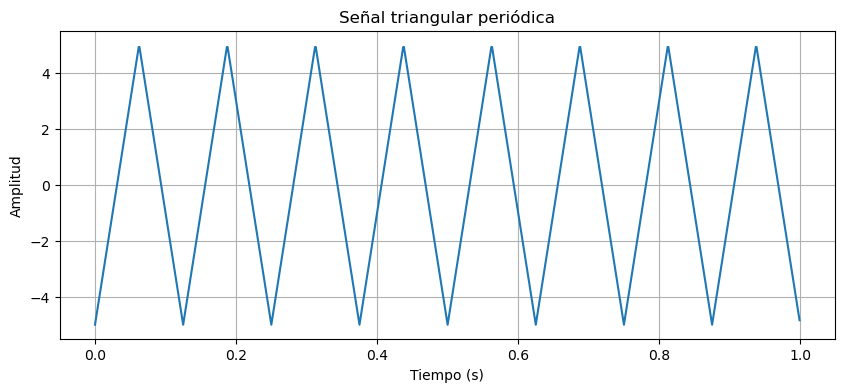

In [5]:

# Parámetros de la señal
f0 = 8       # Frecuencia fundamental en Hz
A = 5       # Amplitud
N = 1000     # Número de muestras
fs = 1000    # Frecuencia de muestreo en Hz

# Vector de tiempo
t = np.arange(N) / fs

# Construcción de la señal triangular
x_triangular = A * sawtooth(2 * np.pi * f0 * t, width=0.5)

# Gráfica de la señal triangular
plt.figure(figsize=(10, 4))
plt.plot(t, x_triangular)
plt.title("Señal triangular periódica")
plt.xlabel("Tiempo (s)")
plt.ylabel("Amplitud")
plt.ylim(-A - 0.5, A + 0.5)
plt.grid(True)
plt.show()



### c) Gráfica de ambas señales en el dominio del tiempo

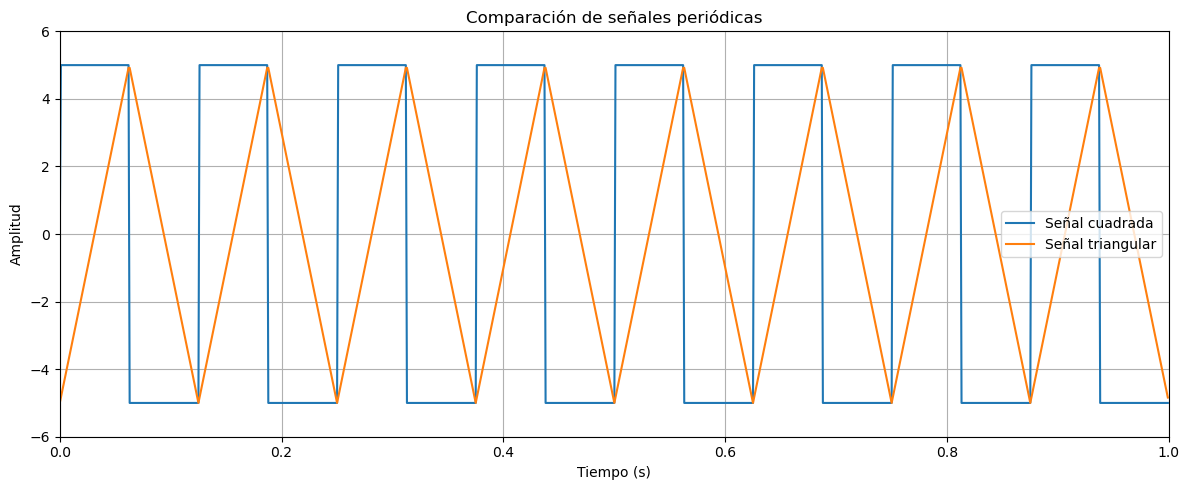

In [6]:

# Gráfica comparativa de las señales existentes

plt.figure(figsize=(12, 5))

plt.plot(t, x, label="Señal cuadrada")
plt.plot(t, x_triangular, label="Señal triangular")

plt.title("Comparación de señales periódicas")
plt.xlabel("Tiempo (s)")
plt.ylabel("Amplitud")
plt.xlim(0, 1)
plt.ylim(-6, 6)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()



### d) y e) Cálculo de los coeficientes de la serie exponencial de Fourier

Se implementó una función que recibe una señal periódica y calcula sus coeficientes de la serie exponencial de Fourier mediante NumPy, utilizando la transformada discreta de Fourier normalizada.

Los coeficientes se calculan mediante la expresión:

$$C_k = \frac{1}{N}\sum_{n=0}^{N-1} x[n]e^{-j\frac{2\pi kn}{N}}$$

donde **x[n]** representa las muestras de un periodo de la señal, **N** es el número de muestras por periodo y **k** es el índice armónico.

La función se aplicó a las señales cuadrada y triangular construidas previamente, seleccionando un periodo completo de cada una para obtener sus respectivos coeficientes.


In [7]:
def coeficientes_fourier(x_periodo):
    """
    Calcula los coeficientes exponenciales de Fourier
    de un periodo de una señal periódica.

    Parámetro:
        x_periodo: muestras de un periodo completo.

    Retorna:
        k: índices armónicos.
        Ck: coeficientes complejos de Fourier.
    """
    x_periodo = np.asarray(x_periodo)
    N = len(x_periodo)

    # Transformada discreta de Fourier normalizada
    Ck = np.fft.fft(x_periodo) / N

    # Índices armónicos centrados en cero
    Ck = np.fft.fftshift(Ck)
    k = np.fft.fftshift(np.fft.fftfreq(N, d=1/N))

    return k, Ck


# Seleccionar un periodo completo de cada señal
muestras_periodo = int(fs / f0)

x_cuadrada_periodo = x[:muestras_periodo]
x_triangular_periodo = x_triangular[:muestras_periodo]

# Calcular coeficientes de Fourier
k_cuadrada, Ck_cuadrada = coeficientes_fourier(
    x_cuadrada_periodo
)

k_triangular, Ck_triangular = coeficientes_fourier(
    x_triangular_periodo
)

# Mostrar algunos coeficientes de cada señal
print("Coeficientes de Fourier de la señal cuadrada:")
for i in range(10):
    print(f"k = {k_cuadrada[i]:4.0f}, "
          f"Ck = {Ck_cuadrada[i]:.4f}")

print("\nCoeficientes de Fourier de la señal triangular:")
for i in range(10):
    print(f"k = {k_triangular[i]:4.0f}, "
          f"Ck = {Ck_triangular[i]:.4f}")


Coeficientes de Fourier de la señal cuadrada:
k =  -62, Ck = 0.0000-0.0395j
k =  -61, Ck = -0.0000+0.0415j
k =  -60, Ck = -0.0000-0.0376j
k =  -59, Ck = -0.0000+0.0437j
k =  -58, Ck = -0.0000-0.0357j
k =  -57, Ck = -0.0000+0.0459j
k =  -56, Ck = -0.0000-0.0339j
k =  -55, Ck = -0.0000+0.0484j
k =  -54, Ck = -0.0000-0.0323j
k =  -53, Ck = -0.0000+0.0509j

Coeficientes de Fourier de la señal triangular:
k =  -62, Ck = -0.0006+0.0000j
k =  -61, Ck = -0.0007-0.0000j
k =  -60, Ck = -0.0006-0.0000j
k =  -59, Ck = -0.0007+0.0000j
k =  -58, Ck = -0.0006-0.0000j
k =  -57, Ck = -0.0007-0.0000j
k =  -56, Ck = -0.0006-0.0000j
k =  -55, Ck = -0.0008-0.0000j
k =  -54, Ck = -0.0005-0.0000j
k =  -53, Ck = -0.0008-0.0000j


### f) Función para graficar el espectro de magnitud y de fase

Cada coeficiente $C_k$ es un número complejo que contiene información sobre la magnitud y la fase de cada armónico:

$$C_k = |C_k|\,e^{j\,\arg(C_k)}$$

- El **espectro de magnitud** representa $|C_k|$ en función del índice armónico $k$ e indica la amplitud de cada componente de la señal.
- El **espectro de fase** representa $\arg(C_k)$ en función de $k$ e indica el desfase de cada componente.

La frecuencia de cada armónico es $f_k = kf_0$, donde $f_0$ es la frecuencia fundamental. Por tanto, el eje horizontal puede expresarse en índices armónicos o en Hz.

La función recibe los índices $k$ y los coeficientes $C_k$ calculados en los puntos anteriores, y genera las gráficas de magnitud y fase para las señales cuadrada y triangular.

**Aclaración:** cuando la magnitud de un coeficiente es prácticamente cero, su fase no está definida. Por ello, se asigna un valor de cero para evitar resultados engañosos en la gráfica.

In [28]:
def graficar_espectros(k, Ck, titulo="", k_max=None, umb=1e-10):
    """
    Grafica el espectro de magnitud y el espectro de fase
    a partir de los coeficientes de Fourier calculados anteriormente.

    Parámetros:
        k: índices armónicos de la función.
        Ck: coeficientes complejos de Fourier.
        titulo: nombre de la señal (para saber cuál es).
        k_max: armónico máximo a mostrar (si es None, se muestran todos).
        umb: umbral por debajo del cual la fase se considera 0.
    """
    k = np.asarray(k)
    Ck = np.asarray(Ck)

    # Magnitud y fase
    magnitud = np.abs(Ck)
    fase = np.angle(Ck)
    fase[magnitud < umb] = 0      # Fase sin sentido si la magnitud es ~0

    # Recorte de armónicos a mostrar
    if k_max is not None:
        mascara = np.abs(k) <= k_max
        k, magnitud, fase = k[mascara], magnitud[mascara], fase[mascara]

    fig, ejes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)

    # Espectro de magnitud
    ejes[0].stem(k, magnitud, basefmt=" ", linefmt="#800080")
    ejes[0].set_title(f"Espectro de magnitud - {titulo}")
    ejes[0].set_ylabel(r"$|C_k|$")
    ejes[0].grid(True)

    # Espectro de fase
    ejes[1].stem(k, fase, basefmt=" ", linefmt="#EE0303")
    ejes[1].set_title(f"Espectro de fase - {titulo}")
    ejes[1].set_xlabel("Índice armónico k")
    ejes[1].set_ylabel(r"$\arg(C_k)$ (rad)")
    ejes[1].set_yticks([-np.pi, -np.pi/2, 0, np.pi/2, np.pi])
    ejes[1].set_yticklabels([r"$-\pi$", r"$-\pi/2$", "0", r"$\pi/2$", r"$\pi$"])
    ejes[1].grid(True)

    plt.tight_layout()
    plt.show()

### g) Espectros de magnitud y fase de la señal cuadrada y de la señal triangular

Se aplica la función del punto f) a los coeficientes $C_k$ calculados en los puntos d) y e), con el fin de visualizar y comparar los espectros de ambas señales.

Al ser señales reales, sus espectros cumplen las siguientes propiedades: $|C_{-k}| = |C_k|$, por lo que la magnitud es simétrica, y la fase presenta simetría impar, es decir, $\arg(C_{-k}) = -\arg(C_k)$, siempre que la fase esté definida.

Se espera además que:

- **Señal cuadrada:** presenta principalmente armónicos impares ($k = \pm1, \pm3, \pm5, \dots$), cuyas magnitudes disminuyen aproximadamente como $1/|k|$.
- **Señal triangular:** también presenta principalmente armónicos impares, pero sus magnitudes disminuyen más rápidamente, aproximadamente como $1/k^2$, debido a que la señal es continua y no presenta saltos.

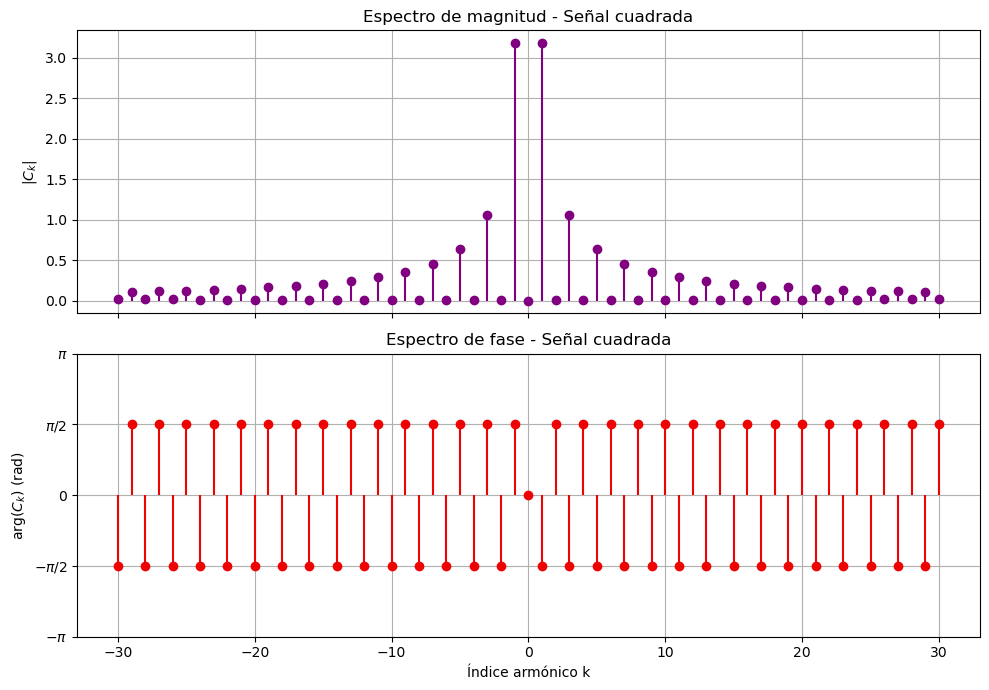

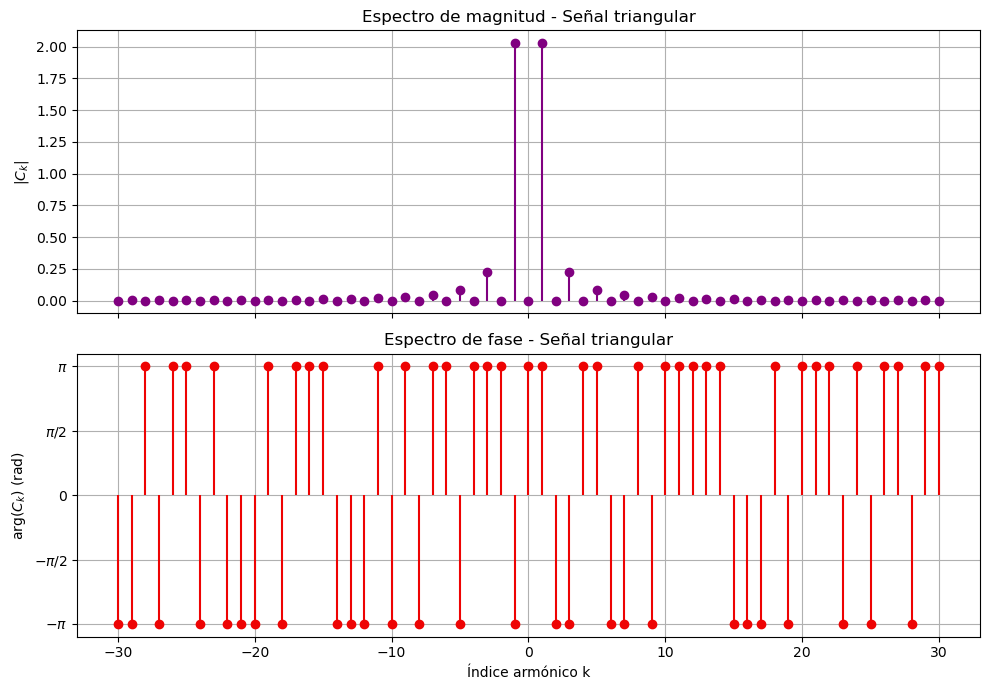

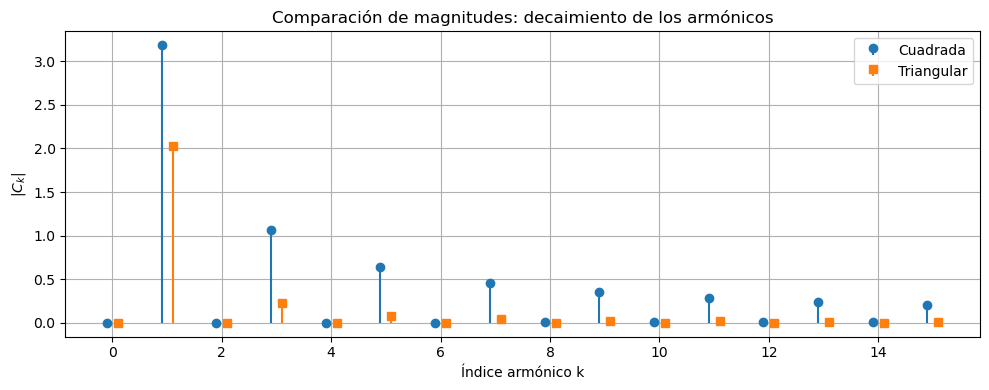

In [30]:
# Se grafica el espectro de Fourier de la señal cuadrada
# k_cuadrada: índices armónicos; Ck_cuadrada: coeficientes
# k_max=30: mostrar hasta el armónico 30
graficar_espectros(k_cuadrada, Ck_cuadrada,
                   titulo="Señal cuadrada", k_max=30)

# Se grafica el espectro de Fourier de la señal triangular
graficar_espectros(k_triangular, Ck_triangular,
                   titulo="Señal triangular", k_max=30)

# Se crea la figura para comparar ambas señales
plt.figure(figsize=(10, 4))

# Seleccionar los armónicos entre k=0 y k=15
ventana = (k_cuadrada >= 0) & (k_cuadrada <= 15)

# Se grafican las magnitudes de la señal cuadrada
# np.abs() calcula el módulo de los coeficientes complejos
# -0.1 desplaza los puntos ligeramente a la izquierda para que no se superpongan con los de la señal triangular
# y poder observar mejor la comparación de magnitudes
plt.stem(k_cuadrada[ventana] - 0.1,
         np.abs(Ck_cuadrada[ventana]),
         linefmt="C0-", markerfmt="C0o",
         basefmt=" ", label="Cuadrada")

# Se grafican las magnitudes de la señal triangular
# +0.1 desplaza los puntos ligeramente a la derecha
plt.stem(k_triangular[ventana] + 0.1,
         np.abs(Ck_triangular[ventana]),
         linefmt="C1-", markerfmt="C1s",
         basefmt=" ", label="Triangular")

# Se agrega título y etiquetas a los ejes
plt.title("Comparación de magnitudes: decaimiento de los armónicos")
plt.xlabel("Índice armónico k")
plt.ylabel(r"$|C_k|$")

#Para mostrar cuadrícula, leyenda y ajustar los espacios
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

### h) Función de reconstrucción de la señal a partir de sus armónicos

Una vez calculados los coeficientes de Fourier, es posible reconstruir la señal sumando sus componentes armónicas. Si se utilizan únicamente los armónicos desde $-K$ hasta $K$, se obtiene una aproximación de la señal original:

$$x[n] \approx \sum_{k=-K}^{K} C_k\,e^{j\frac{2\pi kn}{N}}$$

Donde $K$ representa el número máximo de armónicos utilizados y $N$ es el número de muestras por periodo. Cuantos más armónicos se incluyan, más cercana será la reconstrucción a la señal original.

Como las señales estudiadas son reales, sus coeficientes de Fourier presentan simetría conjugada, es decir, $C_{-k}=C_k^*$. Al combinar los armónicos positivos y negativos, la expresión puede escribirse utilizando cosenos:

$$x[n] \approx C_0 + \sum_{k=1}^{K} 2|C_k|\cos\left(\frac{2\pi kn}{N}+\arg(C_k)\right)$$

Esta forma permite representar cada armónico mediante un coseno cuya amplitud es $2|C_k|$ y cuyo desfase es $\arg(C_k)$. Se utiliza porque facilita la interpretación de las componentes de la señal y permite reconstruirla progresivamente a partir de sus armónicos.

La función recibe los coeficientes de Fourier y el número de armónicos que se desean utilizar para obtener y visualizar la señal reconstruida.

In [37]:
def reconstruir_senal(k, Ck, n_armonicos):
    """
    Reconstruye un periodo de la señal a partir de sus
    coeficientes de Fourier, usando armónicos de -K a K.

    Parámetros:
        k: índices armónicos (centrados en cero).
        Ck: coeficientes complejos de Fourier.
        n_armonicos: número de armónicos K a utilizar.

    Retorna:
        x_rec: señal reconstruida (durante un periodo).
    """
    k = np.asarray(k)
    Ck = np.asarray(Ck)
    N = len(Ck)
    n = np.arange(N)

    # Seleccionar solo los armónicos de -K a K
    mascara = np.abs(k) <= n_armonicos
    k_sel = k[mascara]
    Ck_sel = Ck[mascara]

    # Se usa la primera ecuación de la serie de Fourier para reconstruir la señal
    # Suma de armónicos: x[n] = sum Ck * exp(j*2*pi*k*n/N)
    exponenciales = np.exp(1j * 2 * np.pi * np.outer(n, k_sel) / N)
    x_rec = exponenciales @ Ck_sel

    # La señal es real: se descarta la parte imaginaria (~1e-16)
    return np.real(x_rec)




### i) Reconstrucción progresiva con N = 1, 3, 5, 20 y 50 armónicos

Se reconstruyen la señal cuadrada y la señal triangular utilizando la función del punto h) con $N = 1, 3, 5, 20$ y $50$ armónicos, y se grafica cada reconstrucción junto con la señal original (se grafica un periodo).

Se espera observar que, al aumentar $N$, la aproximación mejora progresivamente: la señal incorpora más detalles hasta parecerse cada vez más a la original.

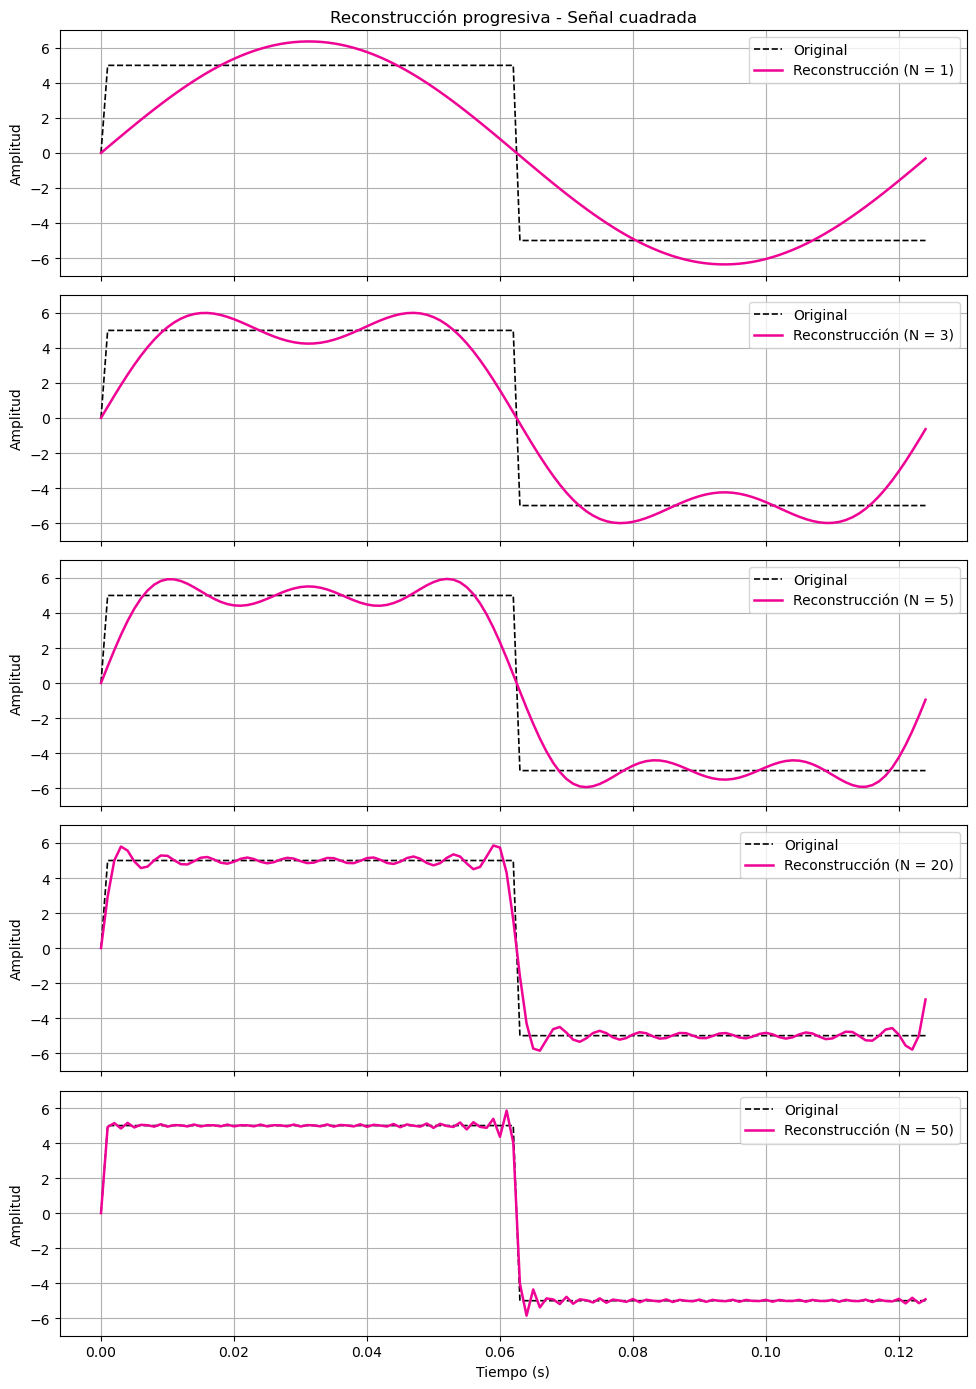

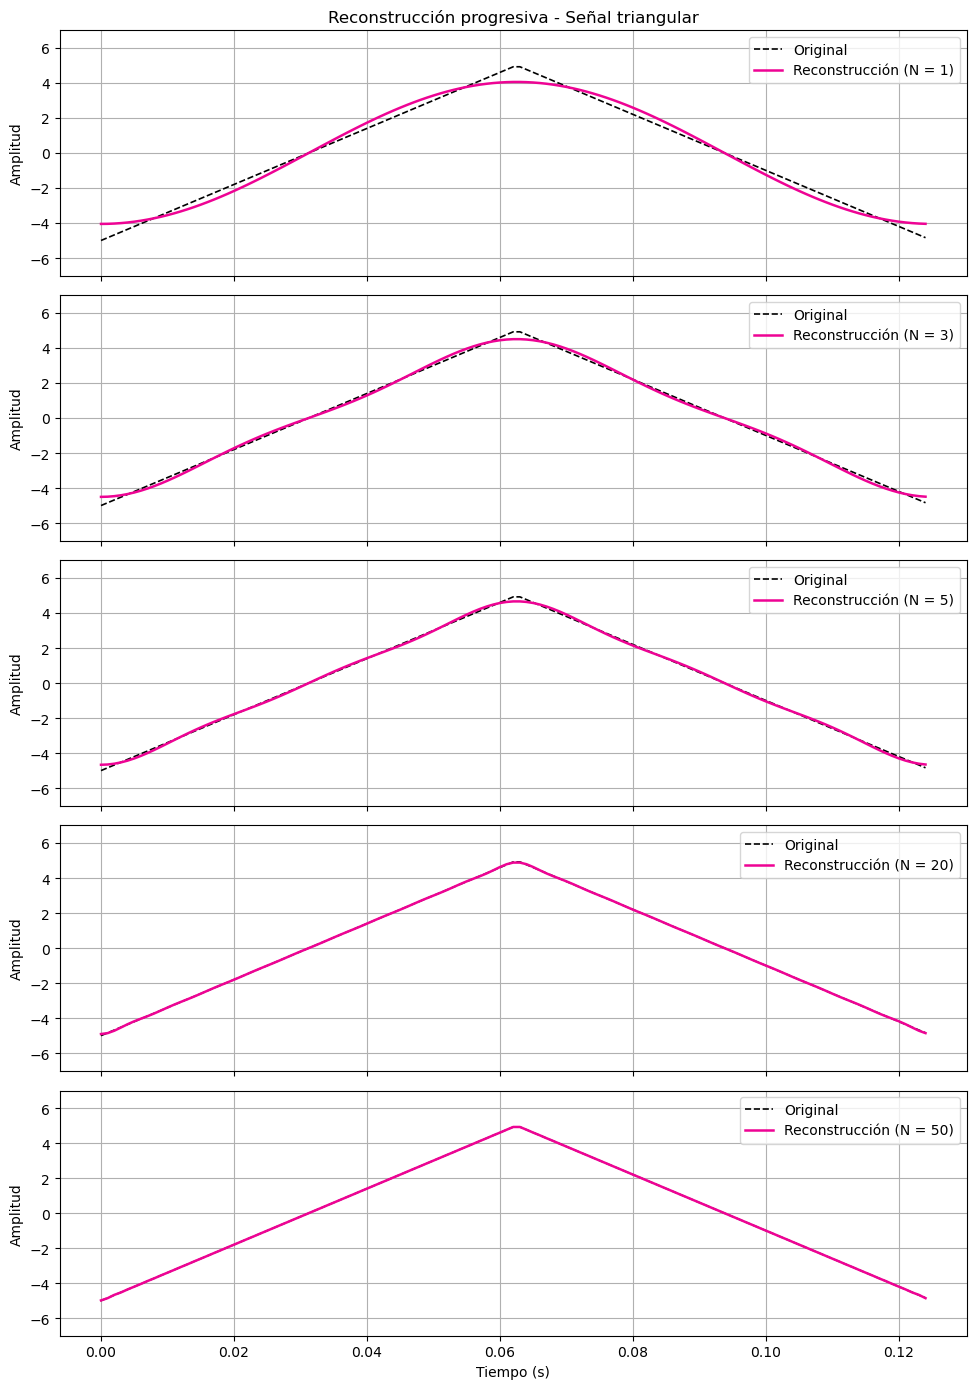

In [ ]:
# Se define la cantidad de armónicos que se usarán en cada reconstrucción
armonicos = [1, 3, 5, 20, 50]

# Eje de tiempo: se selecciona el tiempo correspondiente a un periodo de la señal
t_periodo = t[:muestras_periodo]

# Se crea un diccionario para iterar sobre las señales y sus coeficientes previamente calculados
senales = {
    "Señal cuadrada":   (k_cuadrada,   Ck_cuadrada,   x_cuadrada_periodo),
    "Señal triangular": (k_triangular, Ck_triangular, x_triangular_periodo),
}


#Se crea un ciclo for para iterar sobre las señales y sus coeficientes, 
# reconstruyendo la señal con diferentes números de armónicos y graficando los resultados
for nombre, (k_s, Ck_s, x_orig) in senales.items():
    fig, ejes = plt.subplots(len(armonicos), 1, figsize=(10, 14), sharex=True)

    for eje, n_arm in zip(ejes, armonicos):
        x_rec = reconstruir_senal(k_s, Ck_s, n_arm)

        eje.plot(t_periodo, x_orig, "k--", linewidth=1.2, label="Original")
        eje.plot(t_periodo, x_rec, linewidth=1.8, label=f"Reconstrucción (N = {n_arm})", color="#EE0394")
        eje.set_ylabel("Amplitud")
        eje.set_ylim(-A - 2, A + 2)
        eje.grid(True)
        eje.legend(loc="upper right")

    ejes[0].set_title(f"Reconstrucción progresiva - {nombre}")
    ejes[-1].set_xlabel("Tiempo (s)")
    plt.tight_layout()
    plt.show()

- Se observo que a medida que se aumenta el nuemero de armonicos se ejemplifica con mayor exactitud la señal 

### j) Fenómeno de Gibbs en la señal cuadrada

El fenómeno de Gibbs ocurre cuando se reconstruye una señal discontinua, como una señal cuadrada, mediante una serie de Fourier. Esta serie representa la señal como una suma de ondas sinusoidales de diferentes frecuencias, llamadas armónicos.

Cuando se utilizan pocos armónicos, la señal reconstruida presenta una forma redondeada. Al aumentar su número, la aproximación mejora; sin embargo, cerca de los puntos donde la señal cambia bruscamente de nivel aparecen oscilaciones y sobreoscilaciones que no desaparecen por completo. A este comportamiento se le conoce como **fenómeno de Gibbs**.

Se observa que:
- Al aumentar $N$, la señal reconstruida se parece cada vez más a la onda cuadrada ideal.
- Las oscilaciones se concentran en una región cada vez más estrecha alrededor de los puntos de discontinuidad.
- La señal se caracteriza por tener sobreimpulsos y subimpulsos alrededor de discontinuidades de salto, con un tamaño de sobreimpulso típico de aproximadamente el 8,95% del tamaño del salto.
- Este porcentaje puede variar con respecto a cada señal y se calcula como P= (sobrepico/ salto) x 100%

Esto ocurre porque los senos y cosenos son funciones continuas y suaves, por lo que una suma finita de ellos no puede representar exactamente los cambios instantáneos de nivel de una señal cuadrada. Como consecuencia, al reconstruir la señal con un número limitado de armónicos, aparecen pequeñas oscilaciones cerca de los puntos donde la señal cambia bruscamente de valor. Estas oscilaciones generan un sobrepico que supera el nivel máximo ideal de la señal y una caída por debajo de su nivel mínimo, dando lugar al fenómeno de Gibbs.


Sobrepico de Gibbs en la señal cuadrada:
N =   5 -> máximo = 5.945, sobrepico = 0.945 (9.45 % del salto)
N =  20 -> máximo = 5.860, sobrepico = 0.860 (8.60 % del salto)
N =  30 -> máximo = 5.768, sobrepico = 0.768 (7.68 % del salto)
N =  50 -> máximo = 5.854, sobrepico = 0.854 (8.54 % del salto)


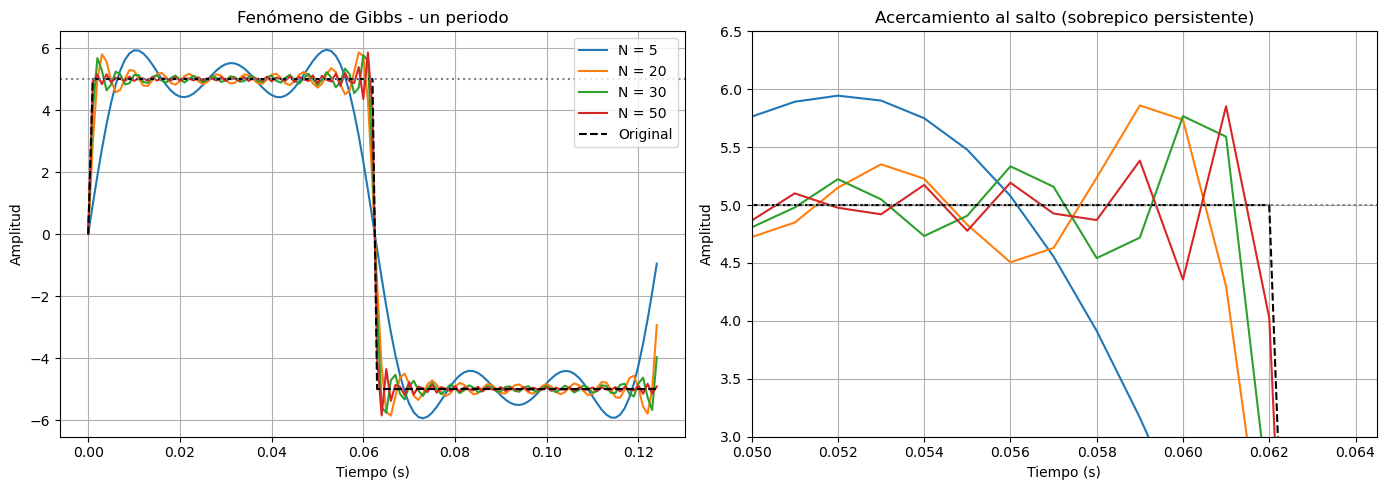

In [42]:
# Se define las cantidades de armónicos para analizar el fenómeno de Gibbs
armonicos_gibbs = [5, 20, 30, 50]

# Se calcula el tamaño del salto de la señal cuadrada, de -A a +A, 
# para poder calcular el sobrepico de Gibbs como porcentaje del salto
salto = 2 * A

# Se mide el sobrepico de Gibbs para cada reconstrucción
print("Sobrepico de Gibbs en la señal cuadrada:")
for n_arm in armonicos_gibbs:

    # Se reconstruye la señal usando la cantidad indicada de 
    # armónicos que se encuentra en la lista armonicos_gibbs
    x_rec = reconstruir_senal(k_cuadrada, Ck_cuadrada, n_arm)

    # Se calcula cuánto supera el máximo reconstruido a la amplitud A
    sobrepico = np.max(x_rec) - A

    # Se muestra el máximo, el sobrepico y su porcentaje respecto al salto
    print(f"N = {n_arm:3d} -> máximo = {np.max(x_rec):.3f}, "
          f"sobrepico = {sobrepico:.3f} "
          f"({100 * sobrepico / salto:.2f} % del salto)")


# se crean dos gráficas para observar el fenómeno de Gibbs
fig, ejes = plt.subplots(1, 2, figsize=(14, 5))

# Se grafican las reconstrucciones con diferentes cantidades de armónicos
for n_arm in armonicos_gibbs:
    x_rec = reconstruir_senal(k_cuadrada, Ck_cuadrada, n_arm)
    ejes[0].plot(t_periodo, x_rec, label=f"N = {n_arm}")
    ejes[1].plot(t_periodo, x_rec, label=f"N = {n_arm}")

# se establecen ambas gráficas y se muestra la señal original 
# para observar la comparacion entre ambas
for eje in ejes:
    eje.plot(t_periodo, x_cuadrada_periodo, "k--", label="Original")
    eje.axhline(A, color="gray", linestyle=":")  # se marca la amplitud A
    eje.grid(True)
    eje.set_xlabel("Tiempo (s)")
    eje.set_ylabel("Amplitud")

# se establecen los títulos de las gráficas
ejes[0].set_title("Fenómeno de Gibbs - un periodo")
ejes[1].set_title("Acercamiento al salto (sobrepico persistente)")

# se amplia la zona cercana a la discontinuidad para observar el sobrepico 
# para poder observar mejor el fenómeno de Gibbs
ejes[1].set_xlim(0.050, 0.0645)
ejes[1].set_ylim(A - 2, A + 1.5)

# se muestra la leyenda, ajustar los espacios y presentar las gráficas
ejes[0].legend(loc="upper right")
plt.tight_layout()
plt.show()

In [ ]:
# Cargar la señal ECG sin ruido
datos = pd.read_csv("ecg_sin_ruido.csv")

ecg = datos["ECG"].to_numpy()

# Parámetros de muestreo
fs = 360  # Frecuencia de muestreo en Hz (ajustar a los datos)
N = len(ecg)

# Vector de tiempo
t = np.arange(N) / fs

# Transformada de Fourier
espectro = np.fft.rfft(ecg)
frecuencias = np.fft.rfftfreq(N, d=1/fs)

# Magnitud normalizada del espectro
magnitud = np.abs(espectro) / N

# Gráficas
fig, ax = plt.subplots(2, 1, figsize=(12, 7))

# ECG en el dominio del tiempo
ax[0].plot(t, ecg)
ax[0].set_title("Señal ECG sin ruido")
ax[0].set_xlabel("Tiempo (s)")
ax[0].set_ylabel("Amplitud")
ax[0].grid(True)

# Composición espectral
ax[1].plot(frecuencias, magnitud)
ax[1].set_title("Composición espectral de la señal ECG")
ax[1].set_xlabel("Frecuencia (Hz)")
ax[1].set_ylabel("Magnitud")
ax[1].set_xlim(0, 60)
ax[1].grid(True)

plt.tight_layout()
plt.show()



### k) Señal ECG sin ruido y composición espectral

Se cargó una señal electrocardiográfica (ECG) sin ruido y se analizó su composición espectral mediante la Transformada Rápida de Fourier (FFT). El análisis en frecuencia permite identificar cómo se distribuye la energía de la señal entre sus diferentes componentes.

Las ondas principales del ECG presentan características espectrales relacionadas con la velocidad de los procesos eléctricos cardíacos:

- **Onda P:** corresponde a la despolarización auricular. Su contenido espectral se concentra principalmente en las frecuencias bajas, generalmente por debajo de 10–15 Hz.
- **Complejo QRS:** representa la despolarización ventricular. Debido a sus cambios rápidos, presenta componentes de mayor frecuencia, con contenido importante aproximadamente entre 5 y 50 Hz.
- **Onda T:** corresponde a la repolarización ventricular. Su variación más lenta hace que su contenido espectral se concentre principalmente por debajo de 10 Hz.

Estas bandas son aproximadas y pueden superponerse, dependiendo de la morfología del ECG y de las condiciones de registro. Por tanto, la composición espectral permite relacionar las variaciones temporales de la señal con los procesos eléctricos del corazón.


In [2]:
%pip install -U kagglehub

Note: you may need to restart the kernel to use updated packages.


In [4]:

import socket

try:
    print(socket.gethostbyname("api.kaggle.com"))
    print("El dominio se está resolviendo correctamente.")
except socket.gaierror:
    print("No se puede resolver api.kaggle.com.")
    print("Revisa tu conexión a Internet o la configuración DNS.")


34.54.168.202
El dominio se está resolviendo correctamente.


In [5]:

import kagglehub

# Descargar la base de datos de ECG
ruta_db = kagglehub.dataset_download(
    "protobioengineering/mit-bih-normal-sinus-rhythm-electrocardiogram-csvs"
)

print("Base de datos descargada en:", ruta_db)


100%|██████████| 1.43G/1.43G [02:20<00:00, 10.9MB/s]

Extracting files...


Base de datos descargada en: C:\Users\JERONIMO\.cache\kagglehub\datasets\protobioengineering\mit-bih-normal-sinus-rhythm-electrocardiogram-csvs\versions\1


In [6]:

from pathlib import Path

carpeta = Path(ruta_db)

for archivo in carpeta.rglob("*"):
    if archivo.is_file():
        print(archivo)


C:\Users\JERONIMO\.cache\kagglehub\datasets\protobioengineering\mit-bih-normal-sinus-rhythm-electrocardiogram-csvs\versions\1\16265_annotations.csv
C:\Users\JERONIMO\.cache\kagglehub\datasets\protobioengineering\mit-bih-normal-sinus-rhythm-electrocardiogram-csvs\versions\1\16265_ekg.csv
C:\Users\JERONIMO\.cache\kagglehub\datasets\protobioengineering\mit-bih-normal-sinus-rhythm-electrocardiogram-csvs\versions\1\16265_metadata.json
C:\Users\JERONIMO\.cache\kagglehub\datasets\protobioengineering\mit-bih-normal-sinus-rhythm-electrocardiogram-csvs\versions\1\16272_annotations.csv
C:\Users\JERONIMO\.cache\kagglehub\datasets\protobioengineering\mit-bih-normal-sinus-rhythm-electrocardiogram-csvs\versions\1\16272_ekg.csv
C:\Users\JERONIMO\.cache\kagglehub\datasets\protobioengineering\mit-bih-normal-sinus-rhythm-electrocardiogram-csvs\versions\1\16272_metadata.json
C:\Users\JERONIMO\.cache\kagglehub\datasets\protobioengineering\mit-bih-normal-sinus-rhythm-electrocardiogram-csvs\versions\1\16273_

In [ ]:
# Buscar los archivos CSV descargados
archivos_csv = list(Path(ruta_db).rglob("*.csv"))

# Mostrar los archivos disponibles
print("Cantidad de archivos CSV:", len(archivos_csv))

for i, archivo in enumerate(archivos_csv):
    print(i, archivo.name)

# Cargar el primer CSV como ejemplo
if archivos_csv:
    ecg_df = pd.read_csv(archivos_csv[1])

    print(ecg_df.head())
    print(ecg_df.shape)
    print(ecg_df.columns)


Cantidad de archivos CSV: 37
0 16265_annotations.csv
1 16265_ekg.csv
2 16272_annotations.csv
3 16272_ekg.csv
4 16273_annotations.csv
5 16273_ekg.csv
6 16420_annotations.csv
7 16420_ekg.csv
8 16483_annotations.csv
9 16483_ekg.csv
10 16539_annotations.csv
11 16539_ekg.csv
12 16773_annotations.csv
13 16773_ekg.csv
14 16786_annotations.csv
15 16786_ekg.csv
16 16795_annotations.csv
17 16795_ekg.csv
18 17052_annotations.csv
19 17052_ekg.csv
20 17453_annotations.csv
21 17453_ekg.csv
22 18177_annotations.csv
23 18177_ekg.csv
24 18184_annotations.csv
25 18184_ekg.csv
26 19088_annotations.csv
27 19088_ekg.csv
28 19090_annotations.csv
29 19090_ekg.csv
30 19093_annotations.csv
31 19093_ekg.csv
32 19140_annotations.csv
33 19140_ekg.csv
34 19830_annotations.csv
35 19830_ekg.csv
36 annotation_symbols.csv


C:\Users\JERONIMO\AppData\Local\Temp\ipykernel_8056\3919180730.py:15: DtypeWarning: Columns (4) have mixed types. Specify dtype option on import or set low_memory=False.
  ecg_df = pd.read_csv(archivos_csv[1])


   Unnamed: 0                  timestamp  voltage_channel_1_mv  \
0           0            0 days 00:00:00                -0.165   
1           1  0 days 00:00:00.007812500                -0.155   
2           2     0 days 00:00:00.015625                -0.195   
3           3  0 days 00:00:00.023437500                -0.205   
4           4     0 days 00:00:00.031250                -0.185   

   voltage_channel_2_mv annotation_symbol  channel  aux_note   num  
0                -0.325               NaN      NaN       NaN   NaN  
1                -0.325                 |     16.0       NaN  11.0  
2                -0.305               NaN      NaN       NaN   NaN  
3                -0.305               NaN      NaN       NaN   NaN  
4                -0.295               NaN      NaN       NaN   NaN  
(11730944, 8)
Index(['Unnamed: 0', 'timestamp', 'voltage_channel_1_mv',
       'voltage_channel_2_mv', 'annotation_symbol', 'channel', 'aux_note',
       'num'],
      dtype='object')


Número de muestras: 1280
Duración del segmento: 10.00 s
Frecuencia de muestreo: 128 Hz


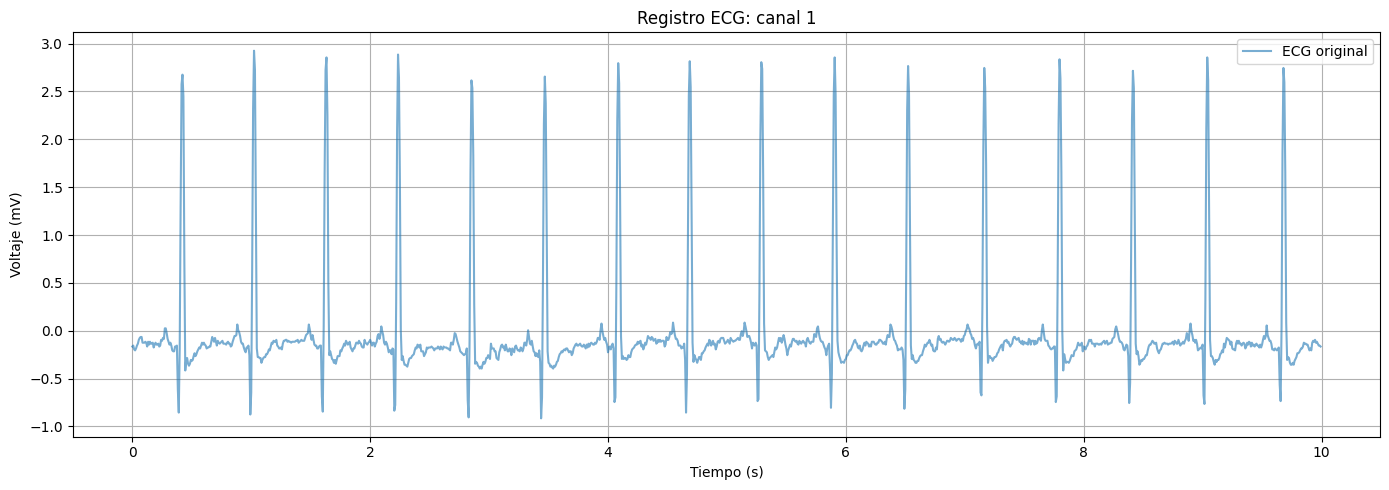

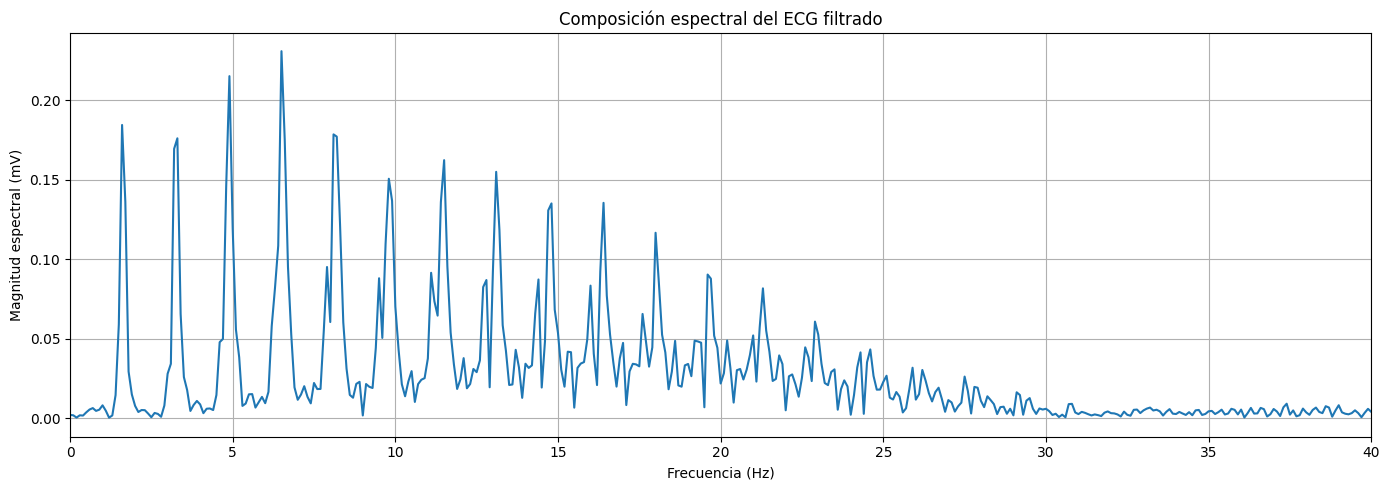

Diez componentes espectrales de mayor magnitud:
 Frecuencia (Hz)  Magnitud (mV)
             6.5       0.230680
             4.9       0.215004
             1.6       0.184332
             8.1       0.178408
             8.2       0.177000
             3.3       0.175932
             6.6       0.175075
             3.2       0.169333
            11.5       0.162222
            13.1       0.154889


In [13]:
# --------------------------------------------------
# 1. Cargar una parte del archivo ECG
# --------------------------------------------------

nombre_archivo = "16265_ekg.csv"
ruta_archivo = os.path.join(ruta_db, nombre_archivo)

# Leer únicamente el canal 1 y un segmento limitado
# 1280 muestras corresponden a 10 segundos a 128 Hz
ecg_df = pd.read_csv(
    ruta_archivo,
    usecols=["voltage_channel_1_mv"],
    nrows=1280
)

ecg = ecg_df["voltage_channel_1_mv"].to_numpy(dtype=float)

# Eliminar posibles valores no válidos
ecg = ecg[np.isfinite(ecg)]

# Frecuencia de muestreo obtenida de los timestamps
fs = 128  # Hz
N = len(ecg)
t = np.arange(N) / fs

print(f"Número de muestras: {N}")
print(f"Duración del segmento: {N / fs:.2f} s")
print(f"Frecuencia de muestreo: {fs} Hz")


# --------------------------------------------------
# 3. Graficar la señal ECG original y filtrada
# --------------------------------------------------

plt.figure(figsize=(14, 5))
plt.plot(t, ecg, label="ECG original", alpha=0.6)
plt.xlabel("Tiempo (s)")
plt.ylabel("Voltaje (mV)")
plt.title("Registro ECG: canal 1")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# --------------------------------------------------
# 4. Calcular la Transformada Rápida de Fourier (FFT)
# --------------------------------------------------

# Eliminar la componente continua y aplicar ventana Hann
senal = ecg_filtrado - np.mean(ecg_filtrado)
ventana = np.hanning(N)

espectro = np.fft.rfft(senal * ventana)
frecuencias = np.fft.rfftfreq(N, d=1/fs)

# Magnitud normalizada del espectro
magnitud = np.abs(espectro) / np.sum(ventana)
magnitud[1:-1] *= 2

# --------------------------------------------------
# 5. Graficar la composición espectral
# --------------------------------------------------

plt.figure(figsize=(14, 5))
plt.plot(frecuencias, magnitud)
plt.xlabel("Frecuencia (Hz)")
plt.ylabel("Magnitud espectral (mV)")
plt.title("Composición espectral del ECG filtrado")
plt.xlim(0, 40)
plt.grid(True)
plt.tight_layout()
plt.show()

# --------------------------------------------------
# 6. Encontrar las frecuencias de mayor magnitud
# --------------------------------------------------

# Excluir la componente de frecuencia cero
indices = np.argsort(magnitud[1:])[::-1][:10] + 1

resultados = pd.DataFrame({
    "Frecuencia (Hz)": frecuencias[indices],
    "Magnitud (mV)": magnitud[indices]
})

print("Diez componentes espectrales de mayor magnitud:")
print(resultados.sort_values("Magnitud (mV)", ascending=False)
      .to_string(index=False))


### Análisis temporal y espectral de una señal ECG

Se seleccionó el registro `16265_ekg.csv` de la base de datos MIT-BIH Normal Sinus Rhythm y se utilizó el canal 1, expresado en milivoltios, para realizar el análisis temporal y espectral. A partir de los timestamps se estableció una frecuencia de muestreo de 128 Hz.

La composición espectral se obtuvo mediante la Transformada Rápida de Fourier (FFT), lo que permitió representar la magnitud de las componentes frecuenciales presentes en el segmento seleccionado. En un ECG.
- **La onda P:** Representa la despolarización de las aurículas. Es una onda relativamente lenta, suave y de baja amplitud, por lo que su contenido espectral se concentra principalmente en frecuencias bajas.
- **El complejo QRS:** Representa la despolarización de los ventrículos. Sus cambios rápidos y pendientes pronunciadas generan componentes de frecuencia más altas que las de las ondas P y T. Una parte importante de su contenido suele encontrarse entre 10 y 30 Hz.
- **La onda T:** Representa la repolarización ventricular. Su morfología suele ser más ancha y suave que la del complejo QRS, por lo que su contenido espectral se concentra principalmente en las frecuencias bajas.
